# GNN Marker Prediction — North Sea Dataset

Adapted from the Colorado GNN notebook.  
Key changes from the Colorado version:
- Well identifier column: `well_name` (string, e.g. `'11_10_1'`) instead of `wellName` (float)
- Depth column: `DS_INDEX` (float, 0.5-ft steps) instead of `DEPTH` (integer, 1-ft steps)
- Input features: `GR_CLEAN`, `RHOB_CLEAN`, `DTC_CLEAN`, `DEEPRES_CLEAN`, `NEUT_CLEAN` (may contain NaNs → imputed)
- Marker tops: 6 formations (`DUNLIN`, `HORDALAND`, `ROGALAND`, `SHETLAND`, `VESTLAND`, `VIKING`) → n_classes = 7
- Data is **pre-split** into train / valid sets (no need to split manually)
- `start_depth` is derived per-well from the data (no fixed cut-off like 6000 ft)
- `df_log` also carries a `marker_label` text column that can be used for sanity checks


## 1. Imports & Installation

In [1]:
# Uncomment to install on a fresh environment
# !pip install numpy torch torchdata networkx
# !pip install dgl -f https://data.dgl.ai/wheels/repo.html

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import pandas as pd
import networkx as nx
import glob
import time
import os
import dgl
import dgl.data
import dgl.dataloading
import dgl.nn.pytorch as dglnn
import tqdm
import matplotlib.pyplot as plt
import matplotlib.colors as colors
import seaborn as sns
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score,
    recall_score, confusion_matrix, classification_report
)

print("torch:", torch.__version__)
print("dgl  :", dgl.__version__)
print("CUDA :", torch.cuda.is_available())

/Users/fokia/Library/Python/3.9/lib/python/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


torch: 2.0.0
dgl  : 1.0.1
CUDA : False


## 2. Load Data

Update `base_dir` to point to where your parquet files live.

In [2]:
base_dir = "/Users/fokia/CRP_SLB/datasets/north_sea/Transformer/"

df_log_train  = pd.read_parquet(os.path.join(base_dir, "log_train.parquet"))
df_tops_train = pd.read_parquet(os.path.join(base_dir, "tops_train.parquet"))
df_log_valid  = pd.read_parquet(os.path.join(base_dir, "log_valid.parquet"))
df_tops_valid = pd.read_parquet(os.path.join(base_dir, "tops_valid.parquet"))

print("df_log_train :", df_log_train.shape)
print("df_tops_train:", df_tops_train.shape)
print("df_log_valid :", df_log_valid.shape)
print("df_tops_valid:", df_tops_valid.shape)

df_log_train : (8196333, 8)
df_tops_train: (399, 6)
df_log_valid : (1986463, 8)
df_tops_valid: (100, 6)


In [3]:
# Marker / formation names in the tops tables
# Adjust this list if your tops table has different columns
MARKER_COLS = ['DUNLIN', 'HORDALAND', 'ROGALAND', 'SHETLAND', 'VESTLAND', 'VIKING']

# Keep only the known marker columns (drop any extras)
df_tops_train = df_tops_train[MARKER_COLS]
df_tops_valid = df_tops_valid[MARKER_COLS]

# Number of classes = number of markers + 1 (background / below last marker)
N_CLASSES = len(MARKER_COLS) + 1   # 7

print("Marker columns:", MARKER_COLS)
print("N_CLASSES     :", N_CLASSES)
df_tops_train.head()

Marker columns: ['DUNLIN', 'HORDALAND', 'ROGALAND', 'SHETLAND', 'VESTLAND', 'VIKING']
N_CLASSES     : 7


valid_marker_name,DUNLIN,HORDALAND,ROGALAND,SHETLAND,VESTLAND,VIKING
well_name,,,,,,
11_10_1,NaN,1410.76120,3356.29932,3438.32032,NaN,NaN
15_12_17_A,NaN,4127.29672,8205.38084,8835.30212,NaN,10416.66700
15_12_19,NaN,NaN,7936.35196,8704.06852,NaN,9740.81396
15_12_21,NaN,3710.63004,7621.39132,8218.50420,9944.22604,9471.78508
15_12_24_S,NaN,4104.33084,7398.29420,7900.26272,9524.27852,9471.78508


In [30]:
# Input feature columns (may contain NaNs — handled in cleaning function below)
INPUT_FEATURES = ['GR_CLEAN', 'RHOB_CLEAN', 'DEEPRES_CLEAN']

df_log_train.head()

,GR_CLEAN,RHOB_CLEAN,DTC_CLEAN,DEEPRES_CLEAN,NEUT_CLEAN,DS_INDEX,well_name,marker_label
index,,,,,,,,
11337,0.089904,0.181408,NaN,0.449192,NaN,219.660106,11_10_1,UNKNOWN
11338,0.089251,0.181408,NaN,0.449192,NaN,220.160106,11_10_1,UNKNOWN
11339,0.083359,0.184276,NaN,0.429787,NaN,220.660106,11_10_1,UNKNOWN
11340,0.080680,0.184276,NaN,0.429787,NaN,221.160106,11_10_1,UNKNOWN
11341,0.080510,0.185673,NaN,0.374377,NaN,221.660106,11_10_1,UNKNOWN


In [29]:
df_log_train["marker_label"].groupby("marker_label").value_counts()

KeyError: 'marker_label'

## 3. Helper Functions

In [11]:
def well_log_cleaning(
    well_name: str,
    df_log: pd.DataFrame,
    input_features: list,
    depth_col: str = 'DS_INDEX',
    well_col: str = 'well_name'
) -> pd.DataFrame:
    """
    Returns a cleaned dataframe for a single well.
    """
    df_well = df_log[df_log[well_col] == well_name].copy()
    if df_well.empty:
        return df_well

    df_well = df_well.sort_values(depth_col).reset_index(drop=True)

    # Keep only the columns we need
    cols_to_keep = input_features + [depth_col]
    df_well = df_well[cols_to_keep]

    # Impute NaNs: forward-fill → backward-fill → column median
    df_well[input_features] = (
        df_well[input_features]
        .ffill()
        .bfill()
        .fillna(df_well[input_features].median())
    )

    # Fallback for completely all-NaN columns
    if 'GLOBAL_MEDIANS' in globals():
        df_well[input_features] = df_well[input_features].fillna(GLOBAL_MEDIANS)

    # Standardize and clip outliers
    if 'SCALER' in globals():
        df_well[input_features] = SCALER.transform(df_well[input_features])
        df_well[input_features] = df_well[input_features].clip(-10, 10)

    # Drop rows that still have NaN in depth (shouldn't happen, but safety net)
    df_well = df_well.dropna(subset=[depth_col])

    return df_well


In [12]:
def step_function(start_depth: float, end_depth: float, tops_depth: list) -> list:
    """
    Generates integer step-function labels for every 0.5-ft sample between
    start_depth and end_depth.

    Changes vs. Colorado version
    ----------------------------
    - Works with float depths (0.5-ft step) instead of integer feet.
    - Uses np.arange for the depth grid instead of range().
    - Tops are matched with a small tolerance (0.26 ft) to handle float precision.

    Returns
    -------
    List of (depth, label) tuples where label ∈ {1, 2, …, n_tops+1}.
    Returns [(start_depth, 1)] if tops list is empty or ordering is violated.
    """
    if not tops_depth or start_depth >= end_depth:
        return [(start_depth, 1)]

    if not all(tops_depth[i] < tops_depth[i + 1] for i in range(len(tops_depth) - 1)):
        return [(start_depth, 1)]

    STEP = 0.5
    TOL  = 0.26   # tolerance for floating-point depth matching

    depths = np.arange(start_depth, end_depth + STEP / 2, STEP)
    step_values = []
    current_label = 1
    tops_set = set(tops_depth)

    for d in depths:
        # Check whether any top falls within tolerance of this depth sample
        for t in tops_depth:
            if abs(d - t) < TOL:
                current_label += 1
                tops_depth = [x for x in tops_depth if x != t]  # consume matched top
                break
        step_values.append((round(d, 4), current_label))

    return step_values

In [13]:
def create_graph(
    df_well: pd.DataFrame,
    step_values: list,
    depth_col: str = 'DS_INDEX',
    input_features: list = INPUT_FEATURES
) -> dgl.DGLGraph:
    """
    Creates a linear DGL graph from a cleaned well dataframe + step labels.

    Changes vs. Colorado version
    ----------------------------
    - Uses INPUT_FEATURES (5 logs) instead of [GR, Depth, Lat, Long].
    - `pos` is a (N, 1) tensor holding DS_INDEX (no lat/long available by default).
      If lat/long columns are present in df_well they are appended automatically.
    - Length mismatch between df_well and step_values is handled by truncating to
      the shorter of the two (previously this caused silent index errors).
    """
    if len(step_values) == 0:
        return dgl.graph(([], []))

    # Align lengths
    n = min(len(df_well), len(step_values))
    df_well    = df_well.iloc[:n].copy()
    step_values = step_values[:n]

    num_nodes = n
    if num_nodes == 0:
        return dgl.graph(([], []))

    # Linear chain edges
    src = list(range(num_nodes - 1))
    dst = list(range(1, num_nodes))
    g = dgl.graph((src, dst))

    # Features tensor  (N x len(input_features))
    feat_vals = df_well[input_features].values.astype(np.float32)
    g.ndata['features'] = torch.tensor(feat_vals, dtype=torch.float32)

    # Position tensor: depth + optional lat/long
    pos_cols = [depth_col]
    for c in ['Latitude', 'Longitude']:
        if c in df_well.columns:
            pos_cols.append(c)
    pos_vals = df_well[pos_cols].values.astype(np.float32)
    g.ndata['pos'] = torch.tensor(pos_vals, dtype=torch.float32)

    # Labels tensor
    labels = [t[1] for t in step_values]
    g.ndata['label'] = torch.tensor(labels, dtype=torch.int64)

    return g

## 4. Dataset & DataLoader

In [9]:
class WellGraphDataset(Dataset):
    """
    PyTorch Dataset that wraps a set of wells into DGL graphs.

    Changes vs. Colorado version
    ----------------------------
    - Well name column is `well_name` (string) — no float/int casting.
    - Depth column is `DS_INDEX`.
    - `start_depth` defaults to None → per-well minimum depth is used.
    - Well list is built as the intersection of wells present in both
      df_log and df_tops (same logic, but string keys).
    - `max_wells` defaults to None (use all available wells).
    """

    def __init__(
        self,
        df_log: pd.DataFrame,
        df_tops: pd.DataFrame,
        input_features: list,
        depth_col: str = 'DS_INDEX',
        well_col: str = 'well_name',
        start_depth: float = None,
        max_wells: int = None
    ):
        self.df_log = df_log
        self.df_tops = df_tops
        self.input_features = input_features
        self.depth_col = depth_col
        self.well_col = well_col
        self.start_depth = start_depth

        # Build well list: intersection of df_log and df_tops
        log_wells  = set(df_log[well_col].unique())
        tops_wells = set(df_tops.index.tolist())
        well_list  = sorted(log_wells & tops_wells)

        if max_wells is not None:
            well_list = well_list[:max_wells]

        self.well_names = well_list
        print(f"WellGraphDataset: {len(self.well_names)} wells loaded.")

    def __len__(self):
        return len(self.well_names)

    def __getitem__(self, idx):
        well = self.well_names[idx]

        df_wgr = well_log_cleaning(
            well, self.df_log, self.input_features,
            depth_col=self.depth_col, well_col=self.well_col
        )

        if df_wgr.empty:
            return self._empty_graph()

        # Apply start_depth filter if provided
        if self.start_depth is not None:
            df_wgr = df_wgr[df_wgr[self.depth_col] > self.start_depth]

        if df_wgr.empty:
            return self._empty_graph()

        # Get tops for this well
        tops_list = (
            self.df_tops.loc[well].dropna().tolist()
            if well in self.df_tops.index
            else []
        )

        start_d = float(df_wgr[self.depth_col].min())
        end_d   = float(df_wgr[self.depth_col].max())

        labels = step_function(start_d, end_d, sorted(tops_list))

        graph = create_graph(
            df_wgr, labels,
            depth_col=self.depth_col,
            input_features=self.input_features
        )

        if graph.num_nodes() == 0:
            return self._empty_graph()

        return graph

    def _empty_graph(self):
        g = dgl.graph(([], []))
        g.add_nodes(1)
        g.ndata['features'] = torch.zeros(1, len(self.input_features), dtype=torch.float32)
        g.ndata['pos']      = torch.zeros(1, 1, dtype=torch.float32)
        g.ndata['label']    = torch.tensor([0], dtype=torch.int64)
        return g


def collate_graphs(samples):
    valid = [g for g in samples if g.num_nodes() > 0]
    if not valid:
        return dgl.graph(([], []))
    return dgl.batch(valid)

In [11]:
# Build train and validation datasets
# max_wells=None uses all available wells; reduce for quick experiments

train_dataset = WellGraphDataset(
    df_log_train, df_tops_train,
    input_features=INPUT_FEATURES,
    max_wells=None
)

valid_dataset = WellGraphDataset(
    df_log_valid, df_tops_valid,
    input_features=INPUT_FEATURES,
    max_wells=None
)

train_dataloader = DataLoader(train_dataset, batch_size=4, shuffle=True,  collate_fn=collate_graphs)
valid_dataloader = DataLoader(valid_dataset, batch_size=4, shuffle=False, collate_fn=collate_graphs)

print(f"Train batches: {len(train_dataloader)} | Valid batches: {len(valid_dataloader)}")

WellGraphDataset: 399 wells loaded.
WellGraphDataset: 100 wells loaded.
Train batches: 100 | Valid batches: 25


## 5. GNN Model

Same `ImprovedGNN` architecture as the Colorado notebook — only `in_features` and `n_classes` change.

In [16]:
class ImprovedGNN(torch.nn.Module):
    """
    Multi-layer GraphConv with BatchNorm + LeakyReLU + Dropout.
    Architecture unchanged from the Colorado version.
    """
    def __init__(self, in_feats, hidden_sizes, n_classes, dropout=0.1):
        super(ImprovedGNN, self).__init__()
        self.convs = torch.nn.ModuleList()
        self.bns   = torch.nn.ModuleList()
        prev_size  = in_feats
        for h in hidden_sizes:
            self.convs.append(dglnn.GraphConv(prev_size, h))
            self.bns.append(torch.nn.BatchNorm1d(h))
            prev_size = h
        self.fc        = torch.nn.Linear(prev_size, n_classes)
        self.dropout   = torch.nn.Dropout(dropout)
        self.activation = F.leaky_relu

    def forward(self, g, features):
        h = features
        for conv, bn in zip(self.convs, self.bns):
            h = conv(g, h)
            h = bn(h)
            h = self.activation(h)
            h = self.dropout(h)
        return self.fc(h)

In [18]:
# Optional: GAT variant
class ExtendedGAT(nn.Module):
    def __init__(self, in_feats, h_feats, num_classes, num_heads, dropout):
        super(ExtendedGAT, self).__init__()
        self.gat1 = dgl.nn.GATConv(in_feats, h_feats, num_heads)
        self.gat2 = dgl.nn.GATConv(h_feats * num_heads, h_feats, num_heads)
        self.gat3 = dgl.nn.GATConv(h_feats * num_heads, h_feats, num_heads)
        self.dropout = nn.Dropout(dropout)
        self.norm1 = nn.BatchNorm1d(h_feats * num_heads)
        self.norm2 = nn.BatchNorm1d(h_feats * num_heads)
        self.fc = nn.Linear(h_feats * num_heads, num_classes)

    def forward(self, g, in_feat):
        h = self.gat1(g, in_feat)
        h = F.elu(h)
        h = self.norm1(h.view(h.size(0), -1))
        h = self.dropout(h)
        h = self.gat2(g, h)
        h = F.elu(h)
        h = self.norm2(h.view(h.size(0), -1))
        h = self.dropout(h)
        h = self.gat3(g, h)
        h = F.elu(h)
        h = self.dropout(h)
        return self.fc(h.view(h.size(0), -1))

In [19]:
class GraphSAGE(nn.Module):
    def __init__(self, in_feats, h_feats, num_classes):
        super(GraphSAGE, self).__init__()
        self.sage1 = dgl.nn.SAGEConv(in_feats, h_feats, 'mean')
        self.sage2 = dgl.nn.SAGEConv(h_feats, num_classes, 'mean')

    def forward(self, g, in_feat):
        h = self.sage1(g, in_feat)
        h = F.relu(h)
        h = self.sage2(g, h)
        return h

class ExtendedGraphSAGE(nn.Module):
    def __init__(self, in_feats, h_feats, num_classes, dropout):
        super(ExtendedGraphSAGE, self).__init__()
        self.sage1 = dgl.nn.SAGEConv(in_feats, h_feats, 'mean')
        self.linear = nn.Linear(h_feats, h_feats)
        self.sage2 = dgl.nn.SAGEConv(h_feats, h_feats, 'mean')
        self.sage3 = dgl.nn.SAGEConv(h_feats, num_classes, 'mean')
        self.dropout = nn.Dropout(dropout)
        self.norm1 = nn.BatchNorm1d(h_feats)
        self.norm2 = nn.BatchNorm1d(h_feats)

    def forward(self, g, in_feat):
        h = self.sage1(g, in_feat)
        h = F.relu(h)
        h = self.norm1(h)
        h = self.dropout(h)
        h = self.linear(h)  # Apply linear transformation
        h = F.relu(h)
        h = self.sage2(g, h)
        h = F.relu(h)
        h = self.norm2(h)
        h = self.dropout(h)
        h = self.sage3(g, h)
        return h


## 6. Loss, Optimizer & Scheduler

In [33]:
in_features  = len(INPUT_FEATURES)     # 5
hidden_sizes = [128, 256, 256, 128, 64]
n_classes    = N_CLASSES               # 7

model = ImprovedGNN(in_features, hidden_sizes, n_classes, dropout=0.1)

# Class-balanced weights
# Adjust the support counts below based on your actual class distribution,
# or compute them automatically from df_log_train['marker_label'].value_counts()
# Example placeholder counts for 7 classes:
supports = torch.tensor([1000, 800, 600, 500, 400, 300, 200], dtype=torch.float32)
computed_weights = supports.max() / supports

criterion = torch.nn.CrossEntropyLoss(weight=computed_weights)
optimizer = torch.optim.Adam(model.parameters(), lr=0.003)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=30, gamma=0.5)

print(model)

ImprovedGNN(
  (convs): ModuleList(
    (0): GraphConv(in=3, out=128, normalization=both, activation=None)
    (1): GraphConv(in=128, out=256, normalization=both, activation=None)
    (2): GraphConv(in=256, out=256, normalization=both, activation=None)
    (3): GraphConv(in=256, out=128, normalization=both, activation=None)
    (4): GraphConv(in=128, out=64, normalization=both, activation=None)
  )
  (bns): ModuleList(
    (0): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (1-2): 2 x BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (3): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (4): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  )
  (fc): Linear(in_features=64, out_features=7, bias=True)
  (dropout): Dropout(p=0.1, inplace=False)
)


In [40]:
# GAT 

in_features  = len(INPUT_FEATURES)     # 5
hidden_sizes = [128, 256, 256, 128, 64]
n_classes    = N_CLASSES               # 7

# Choose your model architecture here:
MODEL_TYPE = 'ImprovedGNN'  # Options: 'ImprovedGNN', 'ExtendedGAT', 'GraphSAGE', 'ExtendedGraphSAGE'

if MODEL_TYPE == 'ImprovedGNN':
    model = ImprovedGNN(in_features, hidden_sizes, n_classes, dropout=0.1)
elif MODEL_TYPE == 'ExtendedGAT':
    # ExtendedGAT uses 'h_feats' instead of hidden_sizes array
    model = ExtendedGAT(in_feats=in_features, h_feats=128, num_classes=n_classes, num_heads=4, dropout=0.1)
elif MODEL_TYPE == 'GraphSAGE':
    model = GraphSAGE(in_feats=in_features, h_feats=128, num_classes=n_classes)
elif MODEL_TYPE == 'ExtendedGraphSAGE':
    model = ExtendedGraphSAGE(in_feats=in_features, h_feats=128, num_classes=n_classes, dropout=0.1)
else:
    raise ValueError(f"Unknown model type {MODEL_TYPE}")

# Class-balanced weights ...
from collections import Counter
label_counts = Counter()
for g in train_dataset:
    labs = g.ndata['label'].numpy()
    label_counts.update(labs.tolist())
print("Label distribution (raw):", dict(sorted(label_counts.items())))

# # Adjusted labels are clamped to [0, n_classes-1] during training
#adjusted_counts = Counter({k-1: v for k, v in label_counts.items()})
#supports_auto = torch.tensor([adjusted_counts.get(i, 1) for i in range(n_classes)], dtype=torch.float32)
computed_weights = supports_auto.max() / supports_auto
print("Class weights:", computed_weights)

criterion = torch.nn.CrossEntropyLoss(weight=computed_weights)
optimizer = torch.optim.Adam(model.parameters(), lr=0.003)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=30, gamma=0.5)

print(model)


Label distribution (raw): {1: 2790678, 2: 2241359, 3: 1070305, 4: 1502988, 5: 413700, 6: 171429, 7: 5874}
Class weights: tensor([  1.0000,   1.2451,   2.6074,   1.8568,   6.7457,  16.2789, 475.0899])
ImprovedGNN(
  (convs): ModuleList(
    (0): GraphConv(in=3, out=128, normalization=both, activation=None)
    (1): GraphConv(in=128, out=256, normalization=both, activation=None)
    (2): GraphConv(in=256, out=256, normalization=both, activation=None)
    (3): GraphConv(in=256, out=128, normalization=both, activation=None)
    (4): GraphConv(in=128, out=64, normalization=both, activation=None)
  )
  (bns): ModuleList(
    (0): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (1-2): 2 x BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (3): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (4): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  )
  (fc): 

In [34]:
# ── Automatic class-weight computation ────────────────────────────────────────
# Uncomment and run this cell to compute class weights from the training labels.
# Requires iterating through the dataset once (may take a minute for large sets).

from collections import Counter
label_counts = Counter()
for g in train_dataset:
    labs = g.ndata['label'].numpy()
    label_counts.update(labs.tolist())
print("Label distribution (raw):", dict(sorted(label_counts.items())))

# # Adjusted labels are clamped to [0, n_classes-1] during training
adjusted_counts = Counter({k-1: v for k, v in label_counts.items()})
supports_auto = torch.tensor([adjusted_counts.get(i, 1) for i in range(n_classes)], dtype=torch.float32)
computed_weights = supports_auto.max() / supports_auto
print("Class weights:", computed_weights)
criterion = torch.nn.CrossEntropyLoss(weight=computed_weights)

Label distribution (raw): {1: 2790678, 2: 2241359, 3: 1070305, 4: 1502988, 5: 413700, 6: 171429, 7: 5874}
Class weights: tensor([  1.0000,   1.2451,   2.6074,   1.8568,   6.7457,  16.2789, 475.0899])


## 7. Training

In [ ]:
def train_gnn(model, train_dataloader, optimizer, criterion, scheduler, n_classes, epochs=50):
    model.train()
    loss_history, accuracy_history = [], []
    precision_history, recall_history, f1_history = [], [], []

    for epoch in range(epochs):
        total_loss = 0.0
        all_preds, all_labels = [], []

        for batch_graphs in train_dataloader:
            if batch_graphs.num_nodes() == 0:
                continue
            batch_graphs = dgl.add_self_loop(batch_graphs)
            optimizer.zero_grad()

            features        = batch_graphs.ndata['features']
            labels          = batch_graphs.ndata['label']
            labels_adjusted = torch.clamp(labels - 1, 0, n_classes - 1)

            pred = model(batch_graphs, features)
            loss = criterion(pred, labels_adjusted)
            
            if torch.isnan(loss):
                print("NaN loss encountered. Skipping batch.")
                optimizer.zero_grad()
                continue
            
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()

            total_loss += loss.item()
            all_preds.extend(pred.argmax(dim=1).cpu().numpy())
            all_labels.extend(labels_adjusted.cpu().numpy())

        avg_loss  = total_loss / max(len(train_dataloader), 1)
        accuracy  = accuracy_score(all_labels, all_preds)
        precision = precision_score(all_labels, all_preds, average='weighted', zero_division=0)
        recall    = recall_score(all_labels, all_preds, average='weighted', zero_division=0)
        f1        = f1_score(all_labels, all_preds, average='weighted', zero_division=0)

        loss_history.append(avg_loss)
        accuracy_history.append(accuracy)
        precision_history.append(precision)
        recall_history.append(recall)
        f1_history.append(f1)

        print(
            f"Epoch {epoch+1:3d}/{epochs} "
            f"→ Loss: {avg_loss:.4f}  Acc: {accuracy:.4f}  "
            f"P: {precision:.4f}  R: {recall:.4f}  F1: {f1:.4f}"
        )
        scheduler.step()

    return loss_history, accuracy_history, f1_history


In [42]:
import warnings

# Suppress the specific PyTorch TypedStorage deprecation warnings from DGL
warnings.filterwarnings(
    "ignore", 
    message="TypedStorage is deprecated", 
    category=UserWarning
)


In [44]:
loss_hist, acc_hist, f1_hist = train_gnn(
    model, train_dataloader, optimizer, criterion, scheduler,
    n_classes=n_classes, epochs=20
)

Epoch   1/20 → Loss: 1.5215  Acc: 0.5123  P: 0.5343  R: 0.5123  F1: 0.5214
Epoch   2/20 → Loss: 1.4415  Acc: 0.5328  P: 0.5490  R: 0.5328  F1: 0.5385
Epoch   3/20 → Loss: 1.4233  Acc: 0.5334  P: 0.5514  R: 0.5334  F1: 0.5397
Epoch   4/20 → Loss: 1.4115  Acc: 0.5388  P: 0.5600  R: 0.5388  F1: 0.5447
Epoch   5/20 → Loss: 1.4083  Acc: 0.5459  P: 0.5620  R: 0.5459  F1: 0.5499
Epoch   6/20 → Loss: 1.3912  Acc: 0.5499  P: 0.5586  R: 0.5499  F1: 0.5496
Epoch   7/20 → Loss: 1.3997  Acc: 0.5460  P: 0.5599  R: 0.5460  F1: 0.5483
Epoch   8/20 → Loss: 1.4040  Acc: 0.5378  P: 0.5611  R: 0.5378  F1: 0.5466
Epoch   9/20 → Loss: 1.3791  Acc: 0.5577  P: 0.5699  R: 0.5577  F1: 0.5600
Epoch  10/20 → Loss: 1.3740  Acc: 0.5512  P: 0.5665  R: 0.5512  F1: 0.5557
Epoch  11/20 → Loss: 1.3748  Acc: 0.5388  P: 0.5588  R: 0.5388  F1: 0.5421
Epoch  12/20 → Loss: 1.3782  Acc: 0.5547  P: 0.5668  R: 0.5547  F1: 0.5565
Epoch  13/20 → Loss: 1.3747  Acc: 0.5473  P: 0.5676  R: 0.5473  F1: 0.5544
Epoch  14/20 → Loss: 1.36

In [1]:
class GraphSAGE(nn.Module):
    def __init__(self, in_feats, h_feats, num_classes):
        super(GraphSAGE, self).__init__()
        self.sage1 = dgl.nn.SAGEConv(in_feats, h_feats, 'mean')
        self.sage2 = dgl.nn.SAGEConv(h_feats, num_classes, 'mean')

    def forward(self, g, in_feat):
        h = self.sage1(g, in_feat)
        h = F.relu(h)
        h = self.sage2(g, h)
        return h

class ExtendedGraphSAGE(nn.Module):
    def __init__(self, in_feats, h_feats, num_classes, dropout):
        super(ExtendedGraphSAGE, self).__init__()
        self.sage1 = dgl.nn.SAGEConv(in_feats, h_feats, 'mean')
        self.linear = nn.Linear(h_feats, h_feats)
        self.sage2 = dgl.nn.SAGEConv(h_feats, h_feats, 'mean')
        self.sage3 = dgl.nn.SAGEConv(h_feats, num_classes, 'mean')
        self.dropout = nn.Dropout(dropout)
        self.norm1 = nn.BatchNorm1d(h_feats)
        self.norm2 = nn.BatchNorm1d(h_feats)

    def forward(self, g, in_feat):
        h = self.sage1(g, in_feat)
        h = F.relu(h)
        h = self.norm1(h)
        h = self.dropout(h)
        h = self.linear(h)  # Apply linear transformation
        h = F.relu(h)
        h = self.sage2(g, h)
        h = F.relu(h)
        h = self.norm2(h)
        h = self.dropout(h)
        h = self.sage3(g, h)
        return h


NameError: name 'nn' is not defined

## 8. Validation Evaluation

In [45]:
def post_process_predictions(preds, window_size=5):
    """Median filter + Monotonicity enforcement."""
    processed = preds.copy()
    
    # 1. Median smoothing
    for i in range(len(preds)):
        start = max(0, i - window_size // 2)
        end   = min(len(preds), i + window_size // 2 + 1)
        processed[i] = np.median(preds[start:end])
        
    #(Monotonically non-decreasing)
    #for i in range(1, len(processed)):
    #    if processed[i] < processed[i-1]:
    #        processed[i] = processed[i-1]
            
    return processed.astype(int)


In [46]:
import scipy.ndimage
import matplotlib.pyplot as plt
import matplotlib.colors as colors
import torch
import numpy as np
import dgl

def visualize_probability_thresholds(well_name, df_log, df_tops, model, window_size=11):
    # Prepare data and graph (same as prediction pipeline)
    df_wgr = well_log_cleaning(well_name, df_log, INPUT_FEATURES)
    df_wgr = df_wgr.dropna(subset=['DS_INDEX'])
    if df_wgr.empty: 
        print("No valid data for this well.")
        return
    
    tops_list = df_tops.loc[well_name].dropna().tolist() if well_name in df_tops.index else []
    start_d = float(df_wgr['DS_INDEX'].min())
    end_d = float(df_wgr['DS_INDEX'].max())
    step_vals = step_function(start_d, end_d, sorted(tops_list))
    
    graph = create_graph(df_wgr, step_vals)
    graph = dgl.add_self_loop(graph)
    
    # Get Model Probabilities
    model.eval()
    with torch.no_grad():
        logits = model(graph, graph.ndata['features']).cpu().numpy()
        
    exp_preds = np.exp(logits - np.max(logits, axis=1, keepdims=True))
    probs = exp_preds / np.sum(exp_preds, axis=1, keepdims=True)
    smoothed_probs = scipy.ndimage.uniform_filter1d(probs, size=window_size, axis=0)
    
    depths = df_wgr['DS_INDEX'].values
    actual_labels = [t[1] for t in step_vals] # 1-based labels
    
    # Plotting
    fig, axes = plt.subplots(1, 2, figsize=(14, 10), sharey=True, gridspec_kw={'width_ratios': [4, 1]})
    cmap = plt.get_cmap('tab10', n_classes)
    
    # Left Plot: Probability Curves
    for c in range(n_classes):
        axes[0].plot(smoothed_probs[:, c], depths, label=f"Class {c+1}", color=cmap(c), lw=2)
        
    # Draw reference thresholds
    axes[0].axvline(0.3, color='green', linestyle='--', alpha=0.8, label='Threshold 0.3')
    axes[0].axvline(0.4, color='orange', linestyle='--', alpha=0.8, label='Threshold 0.4')
    axes[0].axvline(0.5, color='red', linestyle='--', alpha=0.8, label='Threshold 0.5')
    
    axes[0].invert_yaxis()
    axes[0].set_xlabel("Predicted Probability", fontsize=12)
    axes[0].set_ylabel("Depth (DS_INDEX)", fontsize=12)
    axes[0].set_title(f"Smoothed Probabilities vs Depth | Well: {well_name}", fontsize=14)
    axes[0].legend(loc='upper right')
    axes[0].grid(True, alpha=0.4)
    axes[0].set_xlim(0, 1.05)
    
    # Right Plot: The Actual Ground-Truth Labels
    norm = colors.BoundaryNorm(np.arange(0.5, n_classes + 1.5, 1), ncolors=n_classes)
    axes[1].scatter(np.zeros_like(depths), depths, c=actual_labels, cmap=cmap, s=15, norm=norm)
    axes[1].set_title("Actual Labels")
    axes[1].set_xticks([])
    
    plt.tight_layout()
    plt.show()

# Run it on your example validation well!
visualize_probability_thresholds(example_well, df_log_valid, df_tops_valid, model)


NameError: name 'example_well' is not defined

In [47]:
import scipy.ndimage
import numpy as np

def post_process_predictions_dynamic(logits, window_size=11, class_thresholds=None):
    if class_thresholds is None:
        class_thresholds = {c: 0.40 for c in range(logits.shape[1])}
        
    # 1. Convert logits to probabilities and smooth them
    exp_preds = np.exp(logits - np.max(logits, axis=1, keepdims=True))
    probs = exp_preds / np.sum(exp_preds, axis=1, keepdims=True)
    smoothed_probs = scipy.ndimage.uniform_filter1d(probs, size=window_size, axis=0)
    
    processed = np.zeros(len(smoothed_probs), dtype=int)
    
    # Start at the top layer
    processed[0] = np.argmax(smoothed_probs[0])
    
    for i in range(1, len(processed)):
        current_class = processed[i-1]
        best_transition = current_class
        
        # Sequence-Seeking: Check all deeper classes in order
        for deeper_class in range(current_class + 1, probs.shape[1]):
            required_threshold = class_thresholds.get(deeper_class, 0.40)
            
            # If the deeper class reaches our custom threshold, transition into it!
            if smoothed_probs[i, deeper_class] >= required_threshold:
                best_transition = deeper_class
                break # We break so we hit them in order (e.g. hit 2 before 3)
                
        processed[i] = best_transition
            
    return processed


In [68]:
import os
import pandas as pd
from datetime import datetime

# Define the path where you want to save the metrics
# (You can also name it experiment_log__carbon.csv if you add carbon tracking later)
log_file = "experiment_log.csv"

# Gather your metrics into a dictionary
# Assuming you have CarbonTracker/CodeCarbon variables like total_energy_kwh available.
# If not, you can remove those keys for now!
run_metrics = {
    "timestamp": datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
    "model_type": MODEL_TYPE,  # From the block we just updated
    "val_accuracy": round(val_acc, 4),
    "val_precision": round(val_prec, 4),
    "val_recall": round(val_rec, 4),
    "val_f1_score": round(val_f1, 4),
    # "energy_kwh": total_energy_kwh,  # Uncomment if tracking energy
    # "co2eq_g": total_co2eq_g         # Uncomment if tracking carbon
}

# Convert the dictionary to a single-row DataFrame
df_metrics = pd.DataFrame([run_metrics])

# If the file exists, append without writing the header again
# If it doesn't exist, create it and write the header
if os.path.isfile(log_file):
    df_metrics.to_csv(log_file, mode='a', header=False, index=False)
else:
    df_metrics.to_csv(log_file, mode='w', header=True, index=False)

print(f"✅ Successfully saved {MODEL_TYPE} metrics to {log_file}")


✅ Successfully saved ImprovedGNN metrics to experiment_log.csv


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

plot_df = df_log_train.copy()

# choose fewer bins for speed/readability
n_bins = 200

plot_df["ds_bin"] = pd.cut(
    plot_df["ds_index"],
    bins=n_bins,
    labels=False
)

summary = (
    plot_df
    .groupby(["ds_bin", "marker_label"], observed=True)
    .size()
    .reset_index(name="count")
)

pivoted = (
    summary
    .pivot(index="ds_bin", columns="marker_label", values="count")
    .fillna(0)
    .sort_index()
)

pivoted.plot(figsize=(14, 6))

plt.xlabel("ds_index bin")
plt.ylabel("Count")
plt.title("Marker label counts over discretized ds_index")
plt.legend(title="marker_label", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

Validation — Acc: 0.1078  P: 0.4301  R: 0.1078  F1: 0.1001


KeyboardInterrupt: 

In [69]:
import numpy as np
import random
from sklearn.metrics import recall_score

# We already have raw_logits and labels_adj computed from your validation loop above!
# Make sure they are arrays:
# all_raw_logits = np.array(all_raw_logits) # (You might need to append raw_logits in your loop above)
# all_true_labels = np.array(all_true_labels)

print("Starting Threshold Optimization...")

best_recall = 0.0
best_thresholds = None

# Number of random combinations to try
# 2,000 iterations usually takes less than a minute since we don't re-run the model!
num_iterations = 2000 

for i in range(num_iterations):
    # 1. Generate a random threshold dictionary (values between 0.2 and 0.8)
    # You can adjust the min/max bounds based on your intuition
    temp_thresholds = {
        c: round(random.uniform(0.2, 0.8), 2) for c in range(n_classes)
    }
    
    # 2. Apply the dynamic post-processing using the temp thresholds
    # We use all_raw_logits generated from the validation loop
    temp_proc_preds = post_process_predictions_dynamic(
        all_raw_logits, 
        window_size=11, 
        class_thresholds=temp_thresholds
    )
    
    # 3. Calculate the Recall
    # using average='weighted' or 'macro' depending on your preference
    current_recall = recall_score(all_true_labels, temp_proc_preds, average='weighted', zero_division=0)
    
    # 4. Check if it's our best one yet
    if current_recall > best_recall:
        best_recall = current_recall
        best_thresholds = temp_thresholds
        print(f"[{i:4d}/{num_iterations}] New Best Recall: {best_recall:.4f} -> {best_thresholds}")

print("\n" + "="*50)
print(f"🏆 Optimization Complete!")
print(f"Best Weighted Recall : {best_recall:.4f}")
print(f"Optimal Thresholds   : {best_thresholds}")
print("="*50)


Starting Threshold Optimization...
[   0/2000] New Best Recall: 0.0113 -> {0: 0.32, 1: 0.29, 2: 0.26, 3: 0.38, 4: 0.8, 5: 0.22, 6: 0.52}
[   1/2000] New Best Recall: 0.0113 -> {0: 0.64, 1: 0.43, 2: 0.77, 3: 0.42, 4: 0.3, 5: 0.2, 6: 0.32}
[   2/2000] New Best Recall: 0.0118 -> {0: 0.49, 1: 0.73, 2: 0.36, 3: 0.75, 4: 0.46, 5: 0.39, 6: 0.71}
[   3/2000] New Best Recall: 0.0572 -> {0: 0.79, 1: 0.66, 2: 0.21, 3: 0.45, 4: 0.49, 5: 0.54, 6: 0.28}
[   4/2000] New Best Recall: 0.0576 -> {0: 0.42, 1: 0.63, 2: 0.22, 3: 0.58, 4: 0.24, 5: 0.54, 6: 0.32}
[   6/2000] New Best Recall: 0.0576 -> {0: 0.26, 1: 0.3, 2: 0.56, 3: 0.69, 4: 0.3, 5: 0.62, 6: 0.33}
[   8/2000] New Best Recall: 0.1484 -> {0: 0.54, 1: 0.76, 2: 0.32, 3: 0.51, 4: 0.75, 5: 0.72, 6: 0.76}
[  13/2000] New Best Recall: 0.1515 -> {0: 0.31, 1: 0.47, 2: 0.79, 3: 0.22, 4: 0.75, 5: 0.77, 6: 0.38}
[  24/2000] New Best Recall: 0.2251 -> {0: 0.74, 1: 0.72, 2: 0.78, 3: 0.78, 4: 0.78, 5: 0.59, 6: 0.74}
[ 201/2000] New Best Recall: 0.2707 -> {0: 

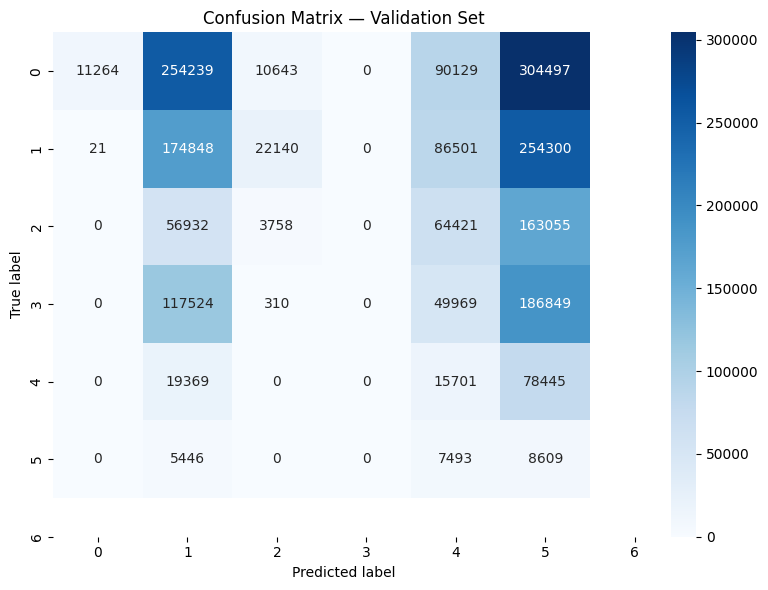

In [63]:
# Confusion matrix
cm = confusion_matrix(all_true_labels, all_proc_preds)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=range(n_classes), yticklabels=range(n_classes))
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title("Confusion Matrix — Validation Set")
plt.tight_layout()
plt.show()

## 9. Per-Well Visualisation

In [51]:
import matplotlib.colors as colors

def plot_well_side_by_side(
    df_well, actual_labels, predicted_labels,
    well_name=None, log_col='GR_CLEAN', depth_col='DS_INDEX'
):
    log_vals = np.array(df_well[log_col])
    depth    = np.array(df_well[depth_col])
    actual   = np.array(actual_labels)
    predicted = np.array(predicted_labels)

    n_ticks   = n_classes
    boundaries = np.arange(0.5, n_ticks + 1.5, 1)
    
    # FIX: Use n_classes so colors don't stretch and max out at Cyan
    norm = colors.BoundaryNorm(boundaries, ncolors=n_classes)
    cmap = plt.get_cmap('tab10', n_classes)

    fig, axes = plt.subplots(1, 2, figsize=(12, 8), sharey=True)

    sc1 = axes[0].scatter(log_vals, depth, c=actual, cmap=cmap, s=10, norm=norm)
    axes[0].invert_yaxis()
    axes[0].set_xlabel(log_col)
    axes[0].set_ylabel("Depth (DS_INDEX)")
    axes[0].set_title(f"Actual\n{well_name}" if well_name else "Actual")

    sc2 = axes[1].scatter(log_vals, depth, c=predicted, cmap=cmap, s=10, norm=norm)
    axes[1].invert_yaxis()
    axes[1].set_xlabel(log_col)
    axes[1].set_title("Predicted")

    fig.subplots_adjust(right=0.82)
    cbar_ax = fig.add_axes([0.85, 0.15, 0.03, 0.7])
    cbar = fig.colorbar(sc2, cax=cbar_ax, ticks=list(range(1, n_ticks + 1)))
    cbar.set_label("Marker Label")

    plt.suptitle(f"Well: {well_name}", fontsize=12)
    plt.tight_layout(rect=[0, 0, 0.82, 1])
    plt.show()


In [52]:
def plot_well_from_name(
    well_name, df_log, df_tops, input_features, model,
    depth_col='DS_INDEX', well_col='well_name'
):
    df_wgr = well_log_cleaning(well_name, df_log, input_features, depth_col, well_col)
    df_wgr = df_wgr.dropna(subset=[depth_col])
    if df_wgr.empty:
        print(f"No valid depth data for well {well_name}")
        return

    tops_list = df_tops.loc[well_name].dropna().tolist() if well_name in df_tops.index else []
    start_d   = float(df_wgr[depth_col].min())
    end_d     = float(df_wgr[depth_col].max())
    step_vals = step_function(start_d, end_d, sorted(tops_list))

    graph = create_graph(df_wgr, step_vals, depth_col=depth_col, input_features=input_features)
    graph = dgl.add_self_loop(graph)

    actual_labels = graph.ndata['label'].cpu().numpy()

    model.eval()
    with torch.no_grad():
        preds = model(graph, graph.ndata['features'])
        
        # Grab the raw logits from the model prediction
        logits = preds.cpu().numpy()
        
        
        # Pass the logits into our new function
        predicted_labels = post_process_predictions_dynamic(
            logits, 
            window_size=11, 
            class_thresholds=my_dynamic_thresholds
        )
        
        predicted_labels = predicted_labels + 1   # back to 1-based for display

    plot_well_side_by_side(df_wgr, actual_labels, predicted_labels, well_name=well_name,
                           depth_col=depth_col)


/var/folders/ss/xj7vz6w928x9h7yd27w3_6_w0000gn/T/ipykernel_59151/2518608765.py:38: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.82, 1])


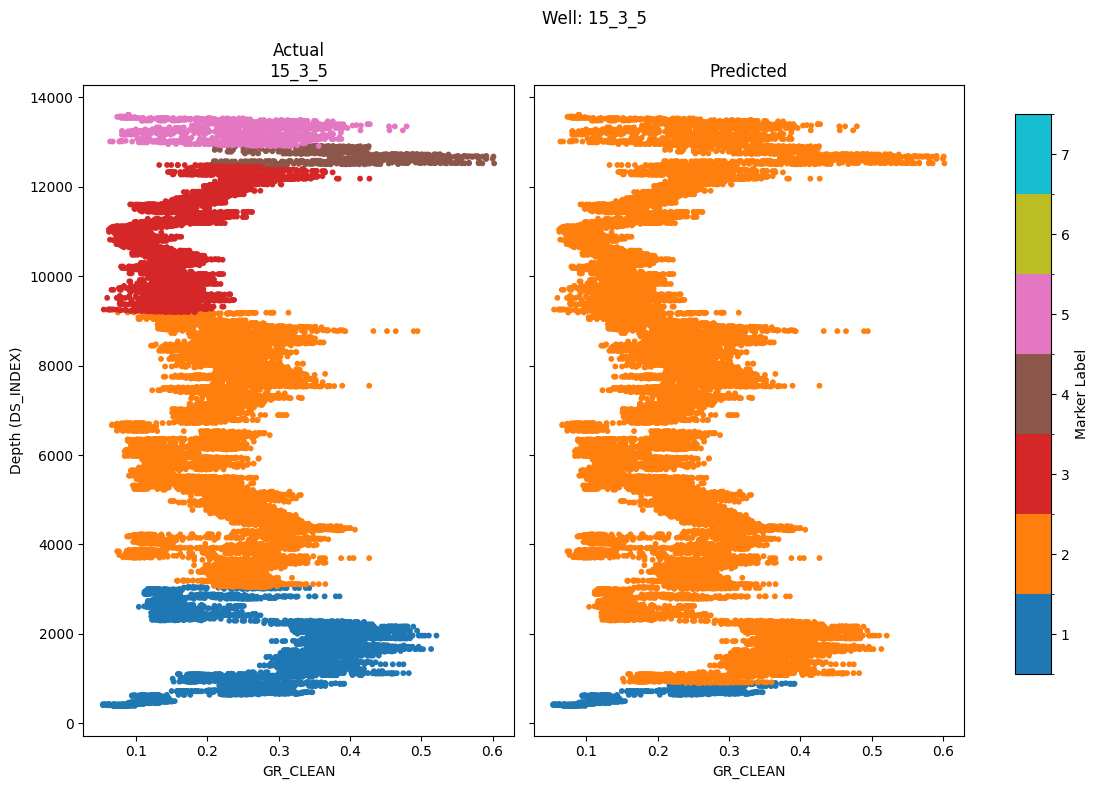

In [53]:
# Example: visualise one validation well
example_well = valid_dataset.well_names[3]
plot_well_from_name(example_well, df_log_valid, df_tops_valid, INPUT_FEATURES, model)

## 10. Predicted Marker Depths & Recall Evaluation

In [54]:
def findIndex(a, n, key):
    """Returns (first_occurrence_index, last_occurrence_index) of key in a."""
    start = -1
    for i in range(n):
        if a[i] == key:
            start = i
            break
    end = start
    if start >= 0:
        for i in range(n - 1, start - 1, -1):
            if a[i] == key:
                end = i
                break
    return (start, end)


def predicted_marker_depths(pred_array, depth_array, n_markers, con='last'):
    """
    Extracts one predicted depth per marker from the prediction array.

    Changes vs. Colorado version
    ----------------------------
    - Generalised to any number of markers (n_markers) instead of hardcoded 3.
    - Returns a dict {marker_index: depth} for easier DataFrame creation.
    - 'first' picks the first index where label == marker_class;
      'last' picks the last index.
    """
    arr = pred_array
    n   = len(arr)
    i   = 0 if con == 'first' else 1

    depths = {}
    for m in range(n_markers):
        label = m + 2   # marker classes start at 2 (1 = background before first marker)
        idx   = findIndex(arr, n, label)
        pos   = idx[i]
        depths[m] = float(depth_array[pos]) if (0 <= pos < len(depth_array)) else np.nan

    return depths

In [61]:
# Generate predictions for all validation wells
n_markers   = len(MARKER_COLS)   # 6
valid_wells = valid_dataset.well_names
records     = []

for idx, well in enumerate(tqdm.tqdm(valid_wells, desc="Predicting")):
    df_wgr = well_log_cleaning(well, df_log_valid, INPUT_FEATURES)
    if df_wgr.empty:
        continue

    tops_list = df_tops_valid.loc[well].dropna().tolist() if well in df_tops_valid.index else []
    start_d   = float(df_wgr['DS_INDEX'].min())
    end_d     = float(df_wgr['DS_INDEX'].max())
    step_vals = step_function(start_d, end_d, sorted(tops_list))

    graph = create_graph(df_wgr, step_vals)
    if graph.num_nodes() == 0:
        continue
    graph = dgl.add_self_loop(graph)

    model.eval()
    with torch.no_grad():
        preds = model(graph, graph.ndata['features']).argmax(dim=1).cpu().numpy()
        preds = post_process_predictions(preds, window_size=5)

    depth_array = [t[0] for t in step_vals]
    pred_depths = predicted_marker_depths(preds, depth_array, n_markers, con='last')

    row = {'well_name': well}
    for m, col in enumerate(MARKER_COLS):
        row[col] = pred_depths[m]
    records.append(row)

df_preds = pd.DataFrame(records).set_index('well_name')
print(df_preds.shape)
df_preds.head()

Predicting: 100%|██████████| 100/100 [00:26<00:00,  3.84it/s]

(100, 6)


,DUNLIN,HORDALAND,ROGALAND,SHETLAND,VESTLAND,VIKING
well_name,,,,,,
10_5_1,5488.1601,5679.1601,6068.1601,5751.1601,NaN,NaN
15_12_12,8021.6601,9090.6601,10115.1601,NaN,NaN,NaN
15_3_2,13196.6601,15401.6601,15597.1601,15066.6601,NaN,NaN
15_3_5,12296.6601,13602.1601,13528.6601,13026.6601,NaN,NaN
15_5_5,8476.6601,8678.1601,8669.1601,NaN,NaN,NaN


In [60]:
def recall_tops(df_tops_true, df_tops_pred, tolerance=10):
    """Unchanged from Colorado version."""
    if set(df_tops_true.columns) != set(df_tops_pred.columns):
        print("Column mismatch:", df_tops_true.columns.tolist(), "vs", df_tops_pred.columns.tolist())
        return None, None, None

    concat_df = df_tops_true.copy()
    for col in df_tops_pred.columns:
        concat_df[col + "_pred"] = df_tops_pred[col]

    tp, p, mae = 0, 0, 0
    for col in df_tops_true.columns:
        p   += concat_df[col].count()
        diff = (concat_df[col] - concat_df[col + "_pred"]).abs()
        tp  += (diff <= tolerance).sum()
        mae += diff.sum()

    return tp / p, mae / p, concat_df

In [58]:
# Align actual tops to predicted wells
df_tops_actual = df_tops_valid.loc[
    df_tops_valid.index.isin(df_preds.index)
].copy()
df_tops_actual = df_tops_actual.reindex(df_preds.index)

recall, mae, df_results = recall_tops(df_tops_actual, df_preds, tolerance=20)
print(f"Recall (±20 ft): {recall:.4f}   MAE: {mae:.2f} ft")
df_results.head()

Recall (±20 ft): 0.0030   MAE: 3319.07 ft


valid_marker_name,DUNLIN,HORDALAND,ROGALAND,SHETLAND,VESTLAND,VIKING,DUNLIN_pred,HORDALAND_pred,ROGALAND_pred,SHETLAND_pred,VESTLAND_pred,VIKING_pred
well_name,,,,,,,,,,,,
10_5_1,NaN,623.35960,885.82680,1099.08140,4829.39648,NaN,5488.1601,5679.1601,6068.1601,5751.1601,NaN,NaN
15_12_12,NaN,4084.64580,7342.51992,8021.65380,NaN,9163.38612,8021.6601,9090.6601,10115.1601,NaN,NaN,NaN
15_3_2,NaN,2198.16280,6830.70888,8818.89792,NaN,13897.63824,13196.6601,15401.6601,15597.1601,15066.6601,NaN,NaN
15_3_5,NaN,3044.61952,NaN,9196.19452,12910.10540,12493.43872,12296.6601,13602.1601,13528.6601,13026.6601,NaN,NaN
15_5_5,NaN,2929.79012,6650.26268,8523.62232,NaN,NaN,8476.6601,8678.1601,8669.1601,NaN,NaN,NaN


## 11. Learning Curve

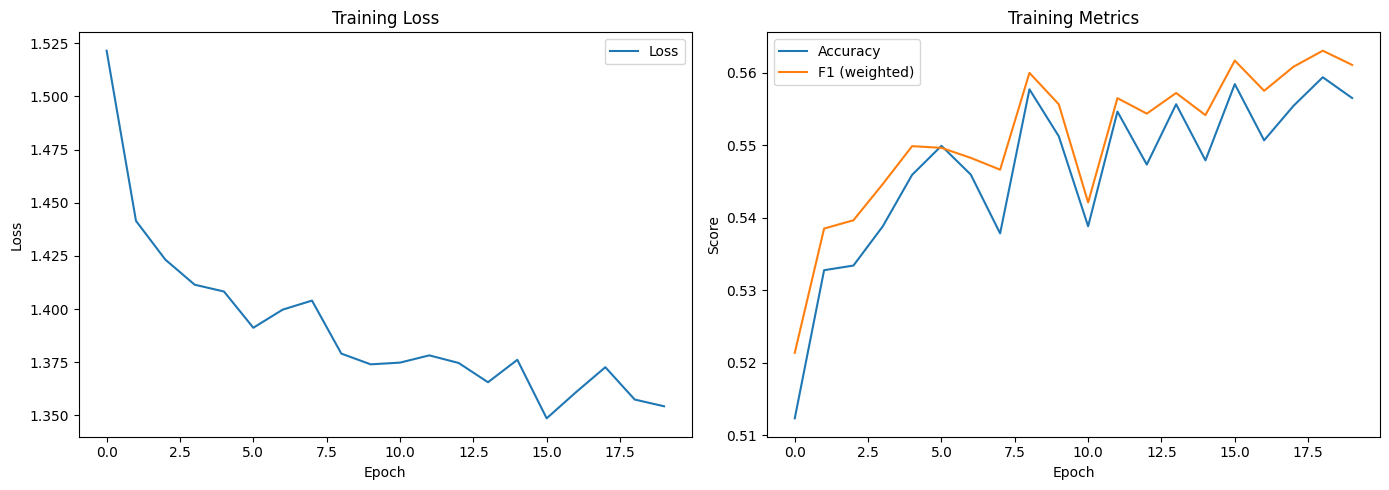

In [59]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(loss_hist, label='Loss')
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss")
axes[0].set_title("Training Loss")
axes[0].legend()

axes[1].plot(acc_hist,  label='Accuracy')
axes[1].plot(f1_hist,   label='F1 (weighted)')
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Score")
axes[1].set_title("Training Metrics")
axes[1].legend()

plt.tight_layout()
plt.show()